In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/btc_1h.csv", parse_dates=["time"])

df["return"] = df["close"].pct_change()

df[["time", "close", "return"]].head()

,time,close,return
0,2026-05-08 18:00:00,80078.40,NaN
1,2026-05-08 19:00:00,80179.94,0.001268
2,2026-05-08 20:00:00,80133.09,-0.000584
3,2026-05-08 21:00:00,80263.99,0.001634
4,2026-05-08 22:00:00,80262.00,-0.000025


In [2]:
print("Average hourly return: ", round(df["return"].mean() * 100, 4), "%")
print("Typical swing (std):   ", round(df["return"].std() * 100, 4), "%")
print("Biggest hourly gain:   ", round(df["return"].max() * 100, 2), "%")
print("Biggest hourly drop:   ", round(df["return"].min() * 100, 2), "%")

Average hourly return:  0.001 %
Typical swing (std):    0.4051 %
Biggest hourly gain:    3.99 %
Biggest hourly drop:    -4.82 %


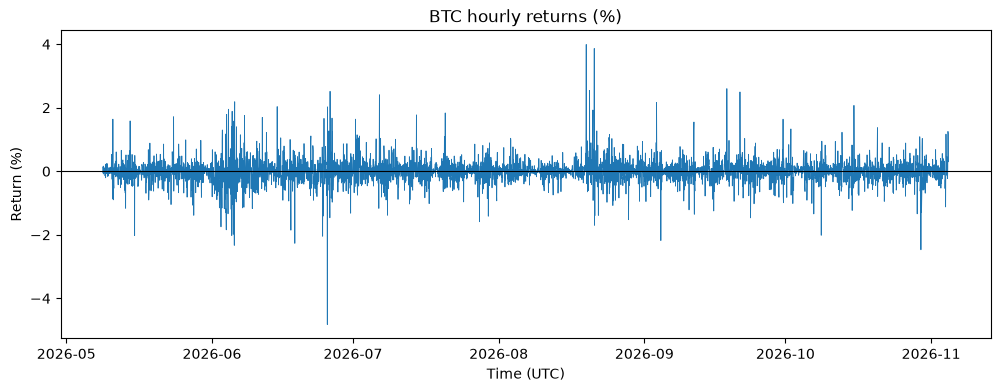

In [3]:
plt.figure(figsize=(12, 4))
plt.plot(df["time"], df["return"] * 100, linewidth=0.6)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("BTC hourly returns (%)")
plt.xlabel("Time (UTC)")
plt.ylabel("Return (%)")
plt.show()

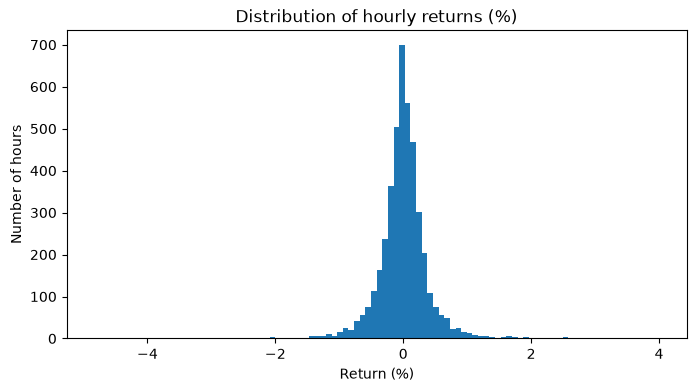

In [4]:
plt.figure(figsize=(8, 4))
plt.hist(df["return"].dropna() * 100, bins=100)
plt.title("Distribution of hourly returns (%)")
plt.xlabel("Return (%)")
plt.ylabel("Number of hours")
plt.show()

In [5]:
up = (df["return"] > 0).sum()
down = (df["return"] < 0).sum()
print("Up hours:  ", up)
print("Down hours:", down)
print("Share of up hours:", round(up / (up + down) * 100, 1), "%")

Up hours:   2149
Down hours: 2169
Share of up hours: 49.8 %


In [6]:
df["ma_20"] = df["close"].rolling(window=20).mean()

df[["time", "close", "ma_20"]].iloc[18:24]

,time,close,ma_20
18,2026-05-09 12:00:00,80397.97,NaN
19,2026-05-09 13:00:00,80391.18,80288.9700
20,2026-05-09 14:00:00,80332.22,80301.6610
21,2026-05-09 15:00:00,80527.92,80319.0600
22,2026-05-09 16:00:00,80625.01,80343.6560
23,2026-05-09 17:00:00,80812.70,80371.0915


In [7]:
df["vol_20"] = df["return"].rolling(window=20).std()

df[["time", "return", "vol_20"]].iloc[19:25]

,time,return,vol_20
19,2026-05-09 13:00:00,-0.000084,NaN
20,2026-05-09 14:00:00,-0.000733,0.001059
21,2026-05-09 15:00:00,0.002436,0.001151
22,2026-05-09 16:00:00,0.001206,0.001155
23,2026-05-09 17:00:00,0.002328,0.001207
24,2026-05-09 18:00:00,0.001175,0.001217


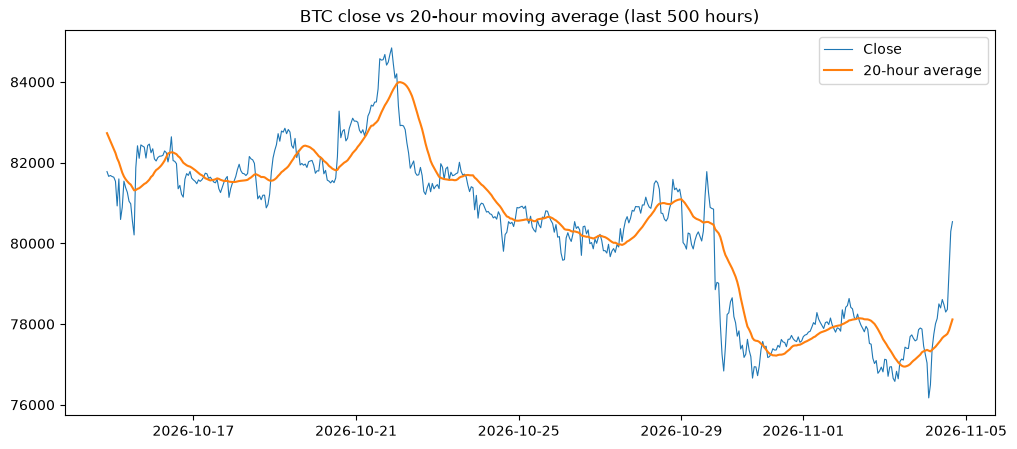

In [8]:
last = df.tail(500)

plt.figure(figsize=(12, 5))
plt.plot(last["time"], last["close"], label="Close", linewidth=0.8)
plt.plot(last["time"], last["ma_20"], label="20-hour average", linewidth=1.5)
plt.title("BTC close vs 20-hour moving average (last 500 hours)")
plt.legend()
plt.show()

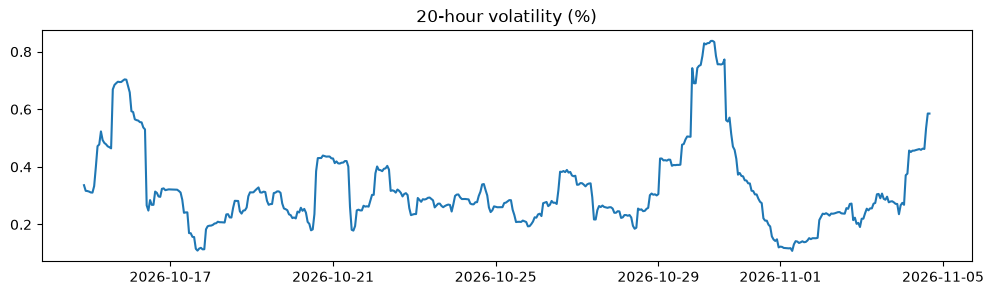

In [9]:
plt.figure(figsize=(12, 3))
plt.plot(last["time"], last["vol_20"] * 100)
plt.title("20-hour volatility (%)")
plt.show()

In [10]:
delta = df["close"].diff()
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

avg_gain = gain.rolling(14).mean()
avg_loss = loss.rolling(14).mean()

rs = avg_gain / avg_loss
df["rsi_14"] = 100 - 100 / (1 + rs)

df[["time", "close", "rsi_14"]].tail()

,time,close,rsi_14
4314,2026-11-04 12:00:00,78298.00,54.535355
4315,2026-11-04 13:00:00,78364.01,60.588335
4316,2026-11-04 14:00:00,79347.33,70.735425
4317,2026-11-04 15:00:00,80296.01,78.055974
4318,2026-11-04 16:00:00,80538.01,92.081914


In [11]:
df["vol_ratio"] = df["volume"] / df["volume"].rolling(20).mean()
df["ret_5"] = df["close"].pct_change(5)
df["dist_ma"] = df["close"] / df["ma_20"] - 1

df[["time", "vol_ratio", "ret_5", "dist_ma"]].tail()

,time,vol_ratio,ret_5,dist_ma
4314,2026-11-04 12:00:00,1.346489,0.002022,0.007405
4315,2026-11-04 13:00:00,1.005468,-0.001732,0.007788
4316,2026-11-04 14:00:00,2.699157,0.012083,0.019278
4317,2026-11-04 15:00:00,4.510154,0.021463,0.029690
4318,2026-11-04 16:00:00,1.780165,0.026259,0.031022


In [12]:
features = df[["time", "close", "return", "ret_5", "vol_20",
               "rsi_14", "vol_ratio", "dist_ma"]].dropna()

print(features.shape)
print(features.isna().sum().sum(), "missing values")

features.to_csv("data/btc_features.csv", index=False)
features.describe().round(4)

(4299, 8)
0 missing values


,time,close,return,ret_5,vol_20,rsi_14,vol_ratio,dist_ma
count,4299,4299.0000,4299.0000,4299.0000,4299.0000,4299.0000,4299.0000,4299.0000
mean,2026-08-07 03:00:00,72649.0247,0.0000,0.0000,0.0036,50.4111,1.0312,-0.0000
min,2026-05-09 14:00:00,58290.1700,-0.0482,-0.0555,0.0005,8.0356,0.1610,-0.0568
25%,2026-06-23 08:30:00,63999.9600,-0.0017,-0.0041,0.0024,38.5697,0.5721,-0.0048
50%,2026-08-07 03:00:00,76402.0100,-0.0000,0.0001,0.0032,50.7328,0.8238,0.0002
75%,2026-09-20 21:30:00,80361.8700,0.0017,0.0039,0.0043,62.0403,1.2258,0.0044
max,2026-11-04 16:00:00,87166.9500,0.0399,0.0637,0.0144,95.6123,9.6609,0.0730
std,NaN,8538.7222,0.0041,0.0087,0.0019,16.4835,0.7358,0.0095


In [13]:
features["next_ret"] = features["return"].shift(-1)
features["next_up"] = (features["next_ret"] > 0).astype(int)

features = features.iloc[:-1]   # last row has no "next hour" yet

features[["time", "return", "next_ret", "next_up"]].tail(3)

,time,return,next_ret,next_up
4315,2026-11-04 13:00:00,0.000843,0.012548,1
4316,2026-11-04 14:00:00,0.012548,0.011956,1
4317,2026-11-04 15:00:00,0.011956,0.003014,1


In [14]:
cols = ["return", "ret_5", "vol_20", "rsi_14", "vol_ratio", "dist_ma"]

features[cols + ["next_ret"]].corr()["next_ret"].drop("next_ret").round(3)

return      -0.016
ret_5       -0.033
vol_20       0.014
rsi_14       0.001
vol_ratio    0.051
dist_ma     -0.016
Name: next_ret, dtype: float64

In [15]:
print(features.groupby(features["return"] > 0)["next_up"].mean().round(3))

return
False    0.522
True     0.473
Name: next_up, dtype: float64
